# Electricity price forecasting with SHAPformer (EPF-DE)

This notebook trains a SHAPformer model on the **EPF-DE** dataset from the [fev-bench](https://github.com/autogluon/fev) benchmark: hourly day-ahead electricity prices in Germany.

1. load the data with the `fev` package,
2. build a dataframe with the covariates of the dataset and calendar features,
3. split the data into training, validation and test data,
4. train the model (or load a trained one).

The switch `TRAINING` decides whether the model is trained from scratch and saved to `MODEL_PATH` (`True`), or whether the trained model is loaded from `MODEL_PATH` (`False`).

In [1]:
%load_ext autoreload
%autoreload 2

import fev
import pandas as pd
import torch
from workalendar.europe import Germany

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from src.models.shapformer import SHAPformer

TRAINING = True  # True: train the model from scratch and save it to MODEL_PATH; False: load the trained model from MODEL_PATH
MODEL_PATH = "epf_de_model.ckpt"

C:\Users\xk5010\shapformer-2\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the data with fev

We load the task definitions of fev-bench and select the EPF-DE task. `task.load_full_dataset()` returns the full dataset as a Hugging Face `datasets.Dataset` with one row per time series. EPF-DE contains a single series (`id = "DE"`) with the target `target` (the price in €/MWh) and two known covariates: the load forecast (`Ampirion Load Forecast`) and the combined PV and wind generation forecast (`PV+Wind Forecast`).

In [2]:
FEV_BENCH_TASKS = "https://raw.githubusercontent.com/autogluon/fev/main/benchmarks/fev_bench/tasks.yaml"

benchmark = fev.Benchmark.from_yaml(FEV_BENCH_TASKS)
task = next(task for task in benchmark.tasks if task.dataset_config == "epf_de")
print(f"Task: {task.task_name}, target: {task.target}, known covariates: {task.known_dynamic_columns}")

dataset = task.load_full_dataset(num_proc=1)
dataset

Task: epf_de, target: target, known covariates: ['Ampirion Load Forecast', 'PV+Wind Forecast']


Dataset({
    features: ['id', 'timestamp', 'target', 'Ampirion Load Forecast', 'PV+Wind Forecast'],
    num_rows: 1
})

## Build the dataframe

The dataframe has one row per hour, indexed by the timestamp. It contains the target `price` and the covariates:

- the covariates of the dataset: `load_forecast` and `pv_wind_forecast`,
- calendar features: `hour_of_day`, `day_of_week` (0 = Monday), `month` and `holiday` (1 on German nationwide public holidays, else 0).

Categorical features must be integers starting at 0, so `month` is shifted from 1–12 to 0–11.

In [3]:
series = dataset.to_pandas().iloc[0]
index = pd.DatetimeIndex(series["timestamp"], name="timestamp")

df = pd.DataFrame(
    {
        "price": series["target"],
        "load_forecast": series["Ampirion Load Forecast"],
        "pv_wind_forecast": series["PV+Wind Forecast"],
    },
    index=index,
)

calendar = Germany()
holidays = {date: calendar.is_holiday(date) for date in set(index.date)}
df["hour_of_day"] = index.hour
df["day_of_week"] = index.day_of_week
df["month"] = index.month - 1  # categorical features must start at 0
df["holiday"] = [int(holidays[date]) for date in index.date]
print(df)

                         price  load_forecast  pv_wind_forecast  hour_of_day  \
timestamp                                                                      
2012-01-09 00:00:00  34.970001       16382.00       3569.527588            0   
2012-01-09 01:00:00  33.430000       15410.50       3315.274902            1   
2012-01-09 02:00:00  32.740002       15595.00       3107.307617            2   
2012-01-09 03:00:00  32.459999       16521.00       2944.620117            3   
2012-01-09 04:00:00  32.500000       17700.75       2897.149902            4   
...                        ...            ...               ...          ...   
2017-12-31 19:00:00   7.920000       16601.00      30649.089844           19   
2017-12-31 20:00:00   4.060000       15977.75      30034.542969           20   
2017-12-31 21:00:00   5.300000       15715.00      29653.007812           21   
2017-12-31 22:00:00   1.860000       15876.00      29520.330078           22   
2017-12-31 23:00:00  -0.920000       151

## Split the data

The data ends on 31 December 2017. We use

- the last 6 months (July–December 2017) as test data,
- the 6 months before (January–June 2017) as validation data,
- everything before (January 2012 – December 2016) as training data.

The test data is removed before training, so `fit` only sees the training and validation data.

In [4]:
TEST_START = df.index[-1].normalize() - pd.DateOffset(months=6) + pd.Timedelta(days=1)
VALIDATION_START = TEST_START - pd.DateOffset(months=6)

train_validation_df = df[df.index < TEST_START]
test_df = df[df.index >= TEST_START]

print(f"Training:   {df.index[0]} to {VALIDATION_START - pd.Timedelta(hours=1)}, "
      f"{(train_validation_df.index < VALIDATION_START).sum()} hours")
print(f"Validation: {VALIDATION_START} to {TEST_START - pd.Timedelta(hours=1)}, "
      f"{(train_validation_df.index >= VALIDATION_START).sum()} hours")
print(f"Test:       {TEST_START} to {df.index[-1]}, {len(test_df)} hours")

Training:   2012-01-09 00:00:00 to 2016-12-31 23:00:00, 43656 hours
Validation: 2017-01-01 00:00:00 to 2017-06-30 23:00:00, 4344 hours
Test:       2017-07-01 00:00:00 to 2017-12-31 23:00:00, 4416 hours


## Create the model

The model predicts the `price` from the covariates in `feature_categories`: for each covariate, the number of categories, or `None` for a continuous feature. As in the TransnetBW example, we use a small transformer with one layer, four attention heads and a hidden dimension of 128.

In [5]:
model = SHAPformer(
    target="price",
    feature_categories={
        "hour_of_day": 24,
        "day_of_week": 7,
        "month": 12,
        "holiday": 2,
        "load_forecast": None,
        "pv_wind_forecast": None,
    },
    d_model=128,
    n_layers=1,
    n_heads=4,
)

## Train the model (or load a trained model)

`model.fit(train_validation_df, VALIDATION_START)` trains on the rows before `VALIDATION_START` and computes the validation loss on the rows from `VALIDATION_START` on. Training runs for at most 100 epochs and stops early when the validation loss has not improved for 10 epochs; the model with the lowest validation loss is restored.

With `TRAINING = True`, the trained model is saved to `MODEL_PATH`; with `TRAINING = False`, it is loaded from there.

In [6]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 100

if TRAINING:
    model.to(DEVICE)
    model = model.fit(train_validation_df, VALIDATION_START, epochs=EPOCHS, batch_size=128)
    torch.save(model, MODEL_PATH)
else:
    model = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
    model.eval()

  0%|          | 0/339 [00:00<?, ?it/s]

  0%|          | 1/339 [00:00<02:05,  2.70it/s]

  1%|          | 3/339 [00:00<00:52,  6.42it/s]

  1%|▏         | 5/339 [00:00<00:39,  8.49it/s]

  2%|▏         | 7/339 [00:00<00:33,  9.79it/s]

  3%|▎         | 9/339 [00:01<00:31, 10.47it/s]

... (11,477 outputs left out)

 99%|█████████▉| 337/339 [00:34<00:00,  9.72it/s]

100%|█████████▉| 338/339 [00:35<00:00,  9.73it/s]

100%|██████████| 339/339 [00:35<00:00,  9.66it/s]

Epoch 35/100, Training loss: 0.29471490907985554, Validation loss: 0.29528034768458156 (best: 0.2809165833397062), Epochs without improvement: 10/10
Early stopping.
Restored the model from epoch 25 with validation loss 0.2809165833397062.


## Evaluate the model on the validation and test data

For each set, we forecast one week (168 hours) from every midnight whose full forecast week lies within the set. We report the mean absolute error (MAE) and the root mean squared error (RMSE) in €/MWh, over the full week and over the first 24 hours (the horizon of the fev-bench task). As a reference, we compare with the weekly seasonal naive forecast, which repeats the price of the week before.

In [7]:
import numpy as np

INPUT_LENGTH = HORIZON = 168


def evaluate(start_time, end_time):
    # forecasts from every midnight in [start_time, end_time) whose forecast week ends before end_time
    positions = np.flatnonzero((df.index >= start_time) & (df.index < end_time) & (df.index.hour == 0))
    positions = [p for p in positions if p + HORIZON <= len(df) and df.index[p + HORIZON - 1] < end_time]
    actual, model_forecast, naive_forecast = [], [], []
    for p in positions:
        past, future = df.iloc[p - INPUT_LENGTH:p], df.iloc[p:p + HORIZON]
        actual.append(future["price"].to_numpy())
        model_forecast.append(model.predict(past, future.drop(columns="price")).to_numpy())
        naive_forecast.append(past["price"].to_numpy())
    actual = np.array(actual)
    rows = {}
    for name, forecast in [("SHAPformer", np.array(model_forecast)), ("Weekly naive", np.array(naive_forecast))]:
        error = forecast - actual
        rows[name] = {
            "MAE (168 h)": np.abs(error).mean(),
            "RMSE (168 h)": np.sqrt((error ** 2).mean()),
            "MAE (24 h)": np.abs(error[:, :24]).mean(),
            "RMSE (24 h)": np.sqrt((error[:, :24] ** 2).mean()),
        }
    return pd.DataFrame(rows).T, len(positions)


results = {}
for name, start_time, end_time in [("Validation", VALIDATION_START, TEST_START),
                                   ("Test", TEST_START, df.index[-1] + pd.Timedelta(hours=1))]:
    results[name], n_forecasts = evaluate(start_time, end_time)
    print(f"{name}: {n_forecasts} forecasts")
pd.concat(results).astype(float).round(2)

Validation: 175 forecasts


Test: 178 forecasts


MAE (168 h)  RMSE (168 h)  MAE (24 h)  RMSE (24 h)
Validation SHAPformer           4.77          8.21        4.42         7.55
           Weekly naive         9.94         15.79       10.39        16.65
Test       SHAPformer           4.60          7.65        4.26         7.24
           Weekly naive        12.70         19.93       12.28        19.20

## Explain one forecast

We explain the forecast of the week starting on Monday, 1 May 2017 (Labour Day, a public holiday). `model.explain(past, future)` splits the forecast into contributions of feature groups: one group per covariate, and one group per day of the past price (`day 1` is the oldest day, `day 7` the most recent one). `base` + the sum of all contributions = `prediction`. For a single forecast, we use the exact method (`method="exact"`), which evaluates the model with all 2<sup>13</sup> feature group subsets.

The explanation is plotted as a stacked area chart around the base value (dotted): positive contributions are stacked above the base, negative ones below it, so the forecast (solid line) lies between the upper and the lower edge of the stack. The dashed line is the actual price.

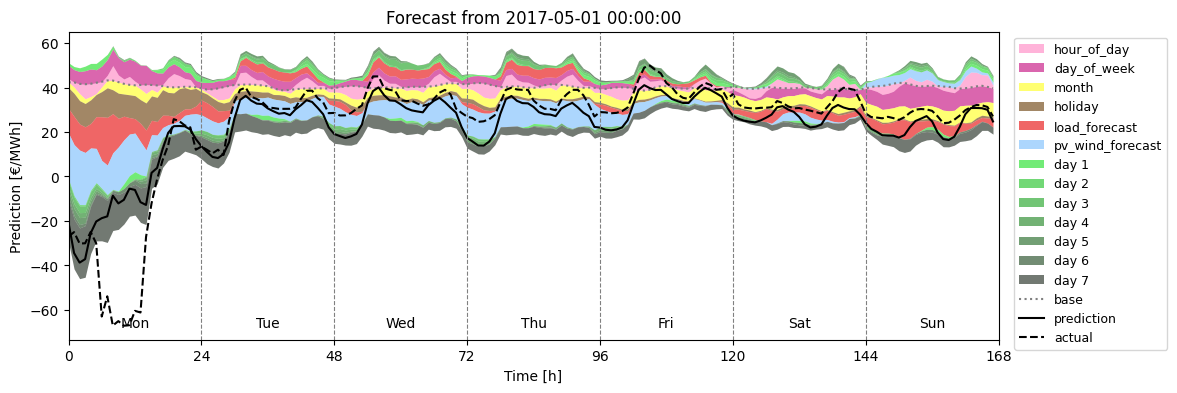

In [8]:
import matplotlib.pyplot as plt
from src.plot import plot_explanation

FORECAST_START = "2017-05-01 00:00:00"

start = df.index.get_loc(FORECAST_START)
past = df.iloc[start - INPUT_LENGTH:start]
future = df.iloc[start:start + HORIZON].drop(columns="price")
actual = df["price"].iloc[start:start + HORIZON]

explanation = model.explain(past, future, method="exact", progress=False)
plot_explanation(explanation, actual=actual, unit="€/MWh", title=f"Forecast from {FORECAST_START}")
plt.show()

## Dependence plots of 1000 explanations

`model.explain(past, future)` splits a forecast into contributions of feature groups: one group per covariate, and one group per day of the past price (`day 1` is the oldest day, `day 7` the most recent one). We explain 1000 forecasts with random starts (at any hour) in the validation and test period, i.e. in the full year 2017, so that all months are covered. We use the fast approximate method `method="permutation"`: it estimates the Owen values from `N_PERMUTATIONS` random orders of the feature groups (each explanation with its own seed for reproducibility), instead of evaluating all 2<sup>13</sup> feature group subsets. `progress=False` turns off the progress bar of each single explanation; instead, one progress bar shows the progress over all explanations.

A dependence plot shows, for one feature, how its value relates to its contribution: each dot is one explained forecast, with the feature value on the x-axis and its SHAP value at the forecasted hour `DEPENDENCE_HORIZON` (here the 24th hour) on the y-axis. For the price, the x-axis is the price one week before that hour, and the y-axis the sum of the contributions of all seven past days. For categorical features, the red line shows the mean contribution per category.

In [9]:
import math
import random
from tqdm import tqdm
from src.plot import plot_dependence

SEED = 42
N_EXPLANATIONS = 1000
N_PERMUTATIONS = 10  # permutations per explanation
DEPENDENCE_HORIZON = 24  # plot the SHAP values of the 24th predicted hour; None plots all 168 hours
N_COLUMNS = 4
UNIT = "€/MWh"

# random forecast starts in the validation and test period (2017);
# the past week of the first starts reaches into the training period
first_validation_start = int((df.index < VALIDATION_START).sum())
starts = random.Random(SEED).sample(range(first_validation_start, len(df) - HORIZON + 1), N_EXPLANATIONS)

explanations = [
    model.explain(df.iloc[s - INPUT_LENGTH:s], df.iloc[s:s + HORIZON].drop(columns="price"),
                  method="permutation", n_permutations=N_PERMUTATIONS, seed=SEED + i, progress=False)
    for i, s in enumerate(tqdm(starts, desc="Explanations"))
]

Explanations:   0%|          | 0/1000 [00:00<?, ?it/s]

Explanations:   0%|          | 2/1000 [00:00<01:14, 13.39it/s]

Explanations:   0%|          | 4/1000 [00:00<01:11, 13.96it/s]

Explanations:   1%|          | 6/1000 [00:00<01:10, 14.19it/s]

Explanations:   1%|          | 8/1000 [00:00<01:08, 14.41it/s]

Explanations:   1%|          | 10/1000 [00:00<01:10, 13.96it/s]

... (492 outputs left out)

Explanations: 100%|█████████▉| 996/1000 [01:25<00:00, 11.50it/s]

Explanations: 100%|█████████▉| 998/1000 [01:25<00:00, 11.63it/s]

Explanations: 100%|██████████| 1000/1000 [01:25<00:00, 11.69it/s]

Explanations: 100%|██████████| 1000/1000 [01:25<00:00, 11.64it/s]

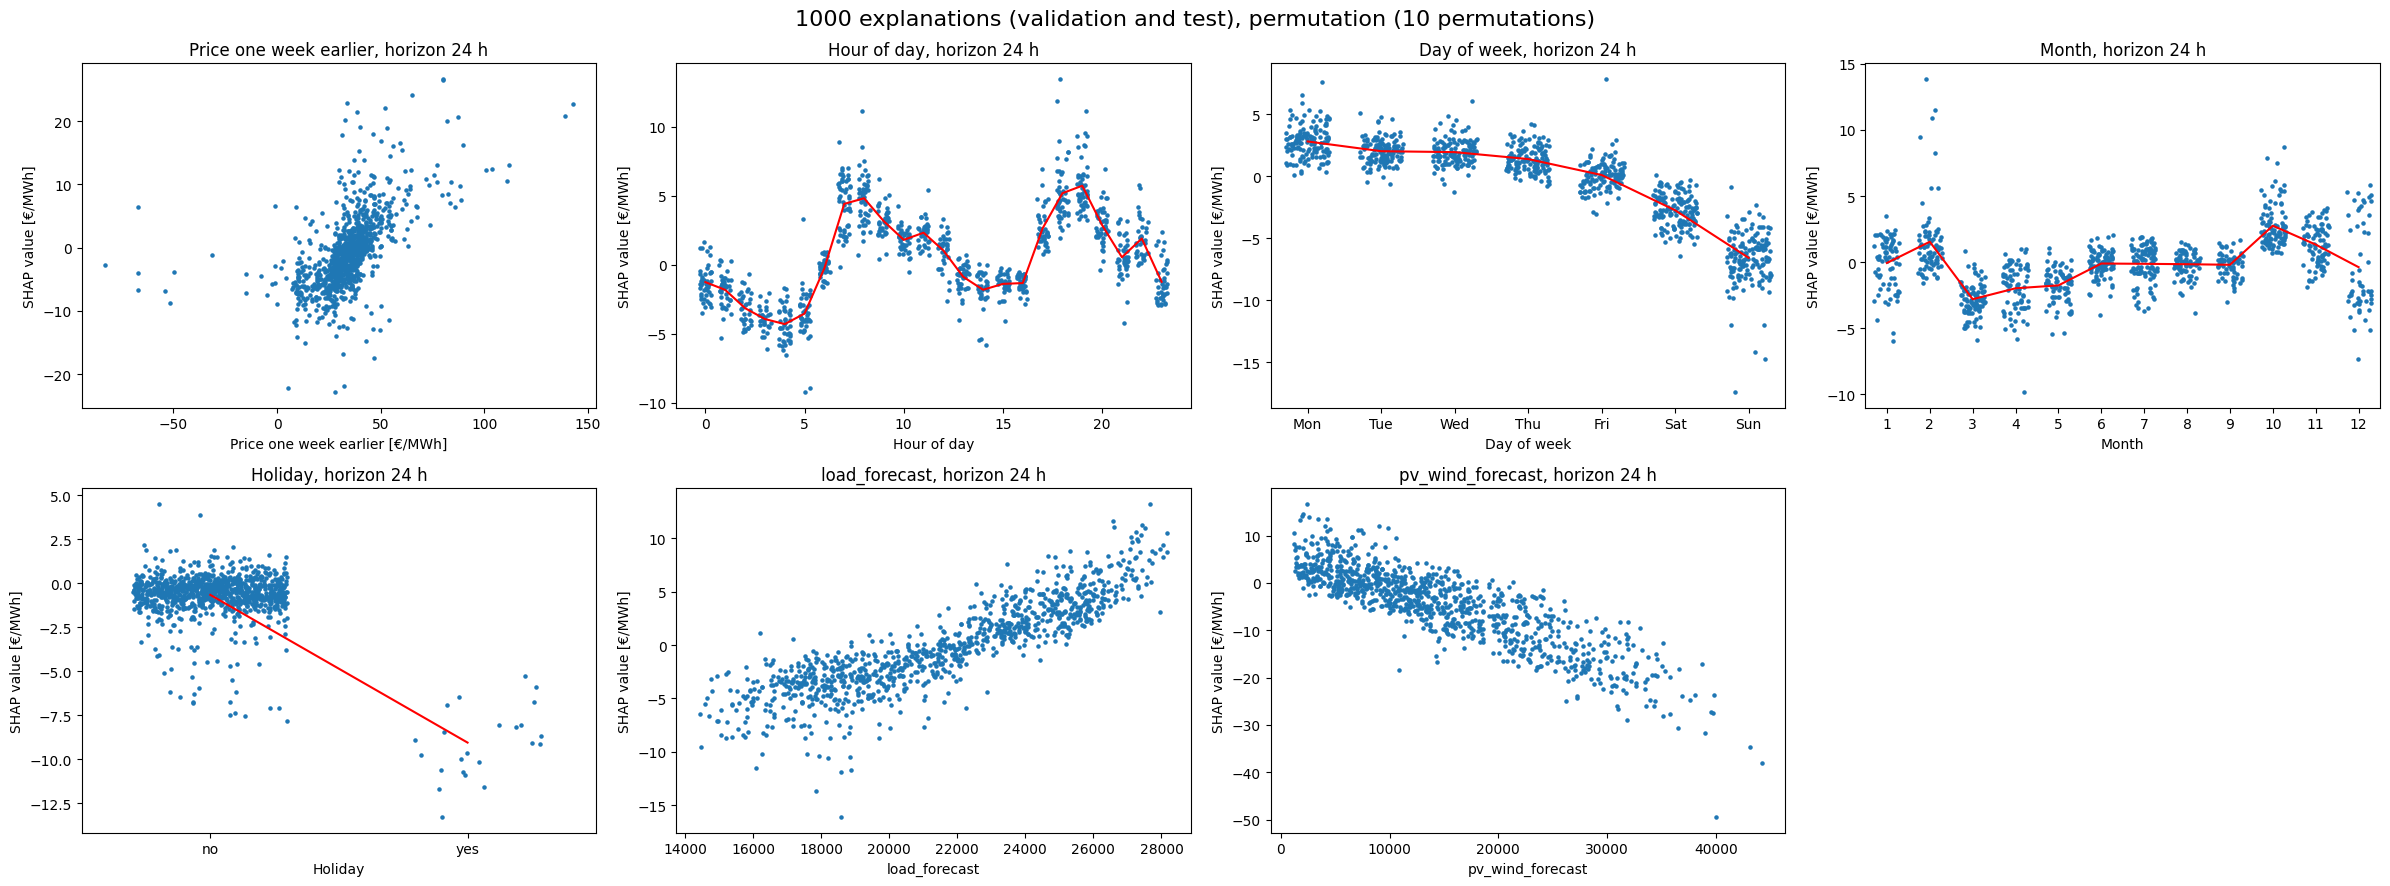

In [10]:
n_rows = math.ceil(len(model.feature_names) / N_COLUMNS)
fig, axs = plt.subplots(n_rows, N_COLUMNS, figsize=(6 * N_COLUMNS, 4.5 * n_rows))
for ax, feature in zip(axs.flat, model.feature_names):
    plot_dependence(explanations, feature, horizon=DEPENDENCE_HORIZON, unit=UNIT, ax=ax)
for ax in axs.flat[len(model.feature_names):]:
    ax.set_visible(False)
fig.suptitle(f"{N_EXPLANATIONS} explanations (validation and test), permutation ({N_PERMUTATIONS} permutations)", fontsize=16)
fig.tight_layout()
plt.show()